In [1]:
# Load labelled and enrolled rows from one consistent data snapshot.
from pathlib import Path
from urllib.request import urlopen
from urllib.error import HTTPError, URLError
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, make_scorer)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

SEED = 42
project = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/clean").is_dir()), Path.cwd())
output_dir = project / "outputs/cem_decision_tree"
model_dir = project / "models"
print("Running all cells writes or replaces result files in:", output_dir.resolve())
print("The saved model will be:", (model_dir / "cem_decision_tree.joblib").resolve())

# Get the current main commit once so all three CSVs come from exactly the same update.
repo = "binds210-learn/mini_project_7"
files = ["selected_features.csv", "enrolled_selected_features.csv", "final_df_clean.csv"]
try:
    with urlopen(f"https://api.github.com/repos/{repo}/commits/main", timeout=15) as response:
        snapshot = json.load(response)["sha"]
    remote = f"https://raw.githubusercontent.com/{repo}/{snapshot}/data/clean"
    tables = []
    for name in files:
        with urlopen(f"{remote}/{name}", timeout=30) as response:
            tables.append(pd.read_csv(response))
    data_source = f"GitHub main at {snapshot}"
except (URLError, TimeoutError, ConnectionError) as error:
    if isinstance(error, HTTPError) and error.code == 404:
        raise FileNotFoundError("A team file or repository path has moved on GitHub. Check data/clean before continuing.") from error
    # Use one complete local set and clearly say its freshness is unverified.
    data_dir = project / "data/clean"
    if not data_dir.is_dir():
        data_dir = project / "mini_project_7/data/clean"
    if not all((data_dir / name).is_file() for name in files):
        raise FileNotFoundError("GitHub was unavailable and the three project CSVs could not be found locally.") from error
    tables = [pd.read_csv(data_dir / name) for name in files]
    data_source = f"LOCAL FILES at {data_dir.resolve()} (GitHub update could not be verified: {error})"

labelled, enrolled, full = tables
print("Data source:", data_source)
print("scikit-learn:", sklearn.__version__)
print("Rows with known outcomes:", len(labelled), "| Still enrolled:", len(enrolled))

Running all cells writes or replaces result files in: C:\Users\cemko\Documents\Ironhack\Week_7\Day_1\mini_project_7\outputs\cem_decision_tree
The saved model will be: C:\Users\cemko\Documents\Ironhack\Week_7\Day_1\mini_project_7\models\cem_decision_tree.joblib
Data source: GitHub main at 77425be48179ca08e05e2d0a5361dd2b96cb66ca
scikit-learn: 1.9.1
Rows with known outcomes: 3630 | Still enrolled: 794


In [2]:
# Give every model the same inputs, training rows, validation rounds and definition of dropout.
nominal = ["application_mode_group", "course_name"]
ordinal = ["prev_qual_level"]
binary = ["debtor", "tuition_fees_up_to_date", "gender", "scholarship_holder"]
s1, s2 = "curricular_units_1st_sem_", "curricular_units_2nd_sem_"
numeric = ["admission_grade", "age_at_enrollment", s2+"enrolled", s2+"approved", s2+"grade", s1+"grade"]
inputs = nominal + ordinal + binary + numeric
assert len(set(inputs)) == 13
# If a column is changed, show exactly what disappeared or was added.
for name, table, expected in [(files[0], labelled, inputs + ["target"]), (files[1], enrolled, inputs)]:
    missing = sorted(set(expected) - set(table.columns))
    added = sorted(set(table.columns) - set(expected))
    if missing or added:
        raise ValueError(f"{name} differs from the agreed 13 inputs. Missing: {missing}. Added: {added}.")
assert set(labelled.target) == {"Dropout", "Graduate"}
X, y = labelled[inputs], labelled["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
folds = list(StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED).split(X_train, y_train))
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label="Dropout", zero_division=0),
    "recall": make_scorer(recall_score, pos_label="Dropout", zero_division=0),
    "f1": make_scorer(f1_score, pos_label="Dropout", zero_division=0),
}
print("Training:", len(X_train), "| Final test:", len(X_test), "| Inputs:", len(inputs))
print("Training rows by label:", y_train.value_counts().to_dict())
print("Practice group sizes:", [len(val) for _, val in folds])

Training: 2904 | Final test: 726 | Inputs: 13
Training rows by label: {'Graduate': 1767, 'Dropout': 1137}
Practice group sizes: [726, 726, 726, 726]


In [3]:
# Learn each preparation rule only from the training students in that round.
def make_preprocessor(nominal_cols, ordinal_cols, numeric_cols, binary_cols):
    return ColumnTransformer([
        ("ordinal", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), MinMaxScaler()), ordinal_cols),
        ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
        ("numerical", MinMaxScaler(), numeric_cols),
        ("binary", "passthrough", binary_cols),
    ])

preprocessor = make_preprocessor(nominal, ordinal, numeric, binary)

def pipeline_for(model, prep=preprocessor):
    return Pipeline([("preprocess", clone(prep)), ("model", model)])

def cv_summary(pipe, features=X_train):
    scores = cross_validate(pipe, features, y_train, cv=folds, scoring=scoring,
                            return_train_score=True, error_score="raise")
    result = {metric: scores["test_" + metric].mean() for metric in scoring}
    result["training_recall"] = scores["train_recall"].mean()
    result["recall_sd"] = scores["test_recall"].std()
    return result

In [4]:
# Check what the tree learns beyond the simplest guess and whether it memorises training cases.
dummy = pipeline_for(DummyClassifier(strategy="most_frequent"))
initial_tree = pipeline_for(DecisionTreeClassifier(random_state=SEED))
rows = {"Majority baseline": cv_summary(dummy), "Unrestricted tree": cv_summary(initial_tree)}
print((100 * pd.DataFrame(rows).T).round(1).to_string())

                   accuracy  precision  recall    f1  training_recall  recall_sd
Majority baseline      60.8        0.0     0.0   0.0              0.0        0.0
Unrestricted tree      85.2       81.3    80.8  81.0            100.0        1.2


In [5]:
# Select the tree settings using practice groups before looking at final-test performance.
grid = {
    "model__max_depth": [2, 3, 4, 6, 8],
    "model__min_samples_leaf": [10, 25, 50],
    "model__class_weight": [None, "balanced"],
}
search = GridSearchCV(initial_tree, grid, cv=folds, scoring=scoring, refit="recall",
                      return_train_score=True, error_score="raise", n_jobs=1)
search.fit(X_train, y_train)
best = search.best_estimator_
tuning = pd.DataFrame(search.cv_results_)
winner = tuning.iloc[search.best_index_]
rows["Tuned decision tree"] = {metric: winner["mean_test_" + metric] for metric in scoring}
rows["Tuned decision tree"].update(training_recall=winner["mean_train_recall"], recall_sd=winner["std_test_recall"])
print("Settings:", search.best_params_)
print("Top three settings by validation recall")
print(tuning.sort_values("rank_test_recall")[["param_model__max_depth", "param_model__min_samples_leaf",
      "param_model__class_weight", "mean_test_recall", "mean_test_precision", "mean_test_f1"]].head(3).round(3).to_string(index=False))

Settings: {'model__class_weight': 'balanced', 'model__max_depth': 2, 'model__min_samples_leaf': 10}
Top three settings by validation recall
 param_model__max_depth  param_model__min_samples_leaf param_model__class_weight  mean_test_recall  mean_test_precision  mean_test_f1
                      2                             10                  balanced             0.854                0.830         0.840
                      2                             25                  balanced             0.854                0.830         0.840
                      6                             50                  balanced             0.846                0.846         0.845


In [6]:
# Compare early, 12-feature, 13-feature and full-data versions on exactly the same training rows.
historical = full.loc[full.target.isin(["Dropout", "Graduate"])].reset_index(drop=True)
pd.testing.assert_frame_equal(historical[labelled.columns], labelled)
pd.testing.assert_frame_equal(full.loc[full.target.eq("Enrolled"), enrolled.columns].reset_index(drop=True), enrolled)
aligned = historical.loc[X_train.index]
fixed_tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=25, class_weight="balanced", random_state=SEED)
first_numeric = ["admission_grade", "age_at_enrollment", s1+"enrolled", s1+"approved", s1+"grade"]
all_nominal = nominal + ["relationship_group", "nationality_group", "mothers_occupation", "fathers_occupation"]
all_ordinal = ordinal + ["mothers_qualification", "fathers_qualification", "application_reordered"]
all_binary = binary + ["daytime_evening_attendance", "displaced", "educational_special_needs", "international"]
all_numeric = [c for c in historical if c not in all_nominal + all_ordinal + all_binary + ["target"]]
feature_sets = {
    "Semester 1 academic measures (12)": (nominal, ordinal, first_numeric, binary),
    "Semester 2 original subset (12)": (nominal, ordinal, numeric[:-1], binary),
    "Both grades, team subset (13)": (nominal, ordinal, numeric, binary),
    "All prepared source predictors (36)": (all_nominal, all_ordinal, all_numeric, all_binary),
}
sensitivity = {}
for name, groups in feature_sets.items():
    test_prep = make_preprocessor(*groups)
    sensitivity[name] = cv_summary(pipeline_for(clone(fixed_tree), test_prep), aligned)
feature_results = pd.DataFrame(sensitivity).T
print((100 * feature_results[["recall", "precision", "f1", "accuracy"]]).round(1).to_string())

                                     recall  precision    f1  accuracy
Semester 1 academic measures (12)      80.4       84.4  82.3      86.5
Semester 2 original subset (12)        83.7       86.6  85.1      88.5
Both grades, team subset (13)          84.3       85.2  84.7      88.1
All prepared source predictors (36)    83.4       86.3  84.8      88.3


In [7]:
# Compare models under one protocol so changing the model is the main difference.
# Use final tuned forest and the settings that won AdaBoost comparison.
# These rows are fresh runs on four folds; each notebook also reports separate scores.
peer_models = {
    "KNN (5 neighbours)": KNeighborsClassifier(n_neighbors=5),
    "Logistic regression": LogisticRegression(C=10, class_weight="balanced", max_iter=1000, random_state=SEED),
    "Random forest (final tuned)": RandomForestClassifier(n_estimators=70, max_depth=11, random_state=SEED, n_jobs=1),
    "Gradient boosting (AdaBoost comparison winner)": GradientBoostingClassifier(n_estimators=70, learning_rate=0.20, max_depth=2, random_state=SEED),
}
for name, model in peer_models.items():
    rows[name] = cv_summary(pipeline_for(model))
comparison = pd.DataFrame(rows).T
print("Mean validation percentages (recall_sd is in percentage points)")
print((100 * comparison[["recall", "precision", "f1", "accuracy", "training_recall", "recall_sd"]]).round(1).to_string())

Mean validation percentages (recall_sd is in percentage points)
                                                recall  precision    f1  accuracy  training_recall  recall_sd
Majority baseline                                  0.0        0.0   0.0      60.8              0.0        0.0
Unrestricted tree                                 80.8       81.3  81.0      85.2            100.0        1.2
Tuned decision tree                               85.4       83.0  84.0      87.3             85.2        2.6
KNN (5 neighbours)                                64.9       85.5  73.8      82.0             74.8        2.8
Logistic regression                               86.2       89.6  87.9      90.7             87.3        1.6
Random forest (final tuned)                       80.5       92.1  85.9      89.6             89.3        1.4
Gradient boosting (AdaBoost comparison winner)    83.6       91.9  87.5      90.7             85.7        0.2


In [8]:
# Count both students missed and unnecessary alerts on the untouched test rows for this run.
pred = best.predict(X_test)
test_metrics = pd.Series({
    "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred, pos_label="Dropout", zero_division=0),
    "recall": recall_score(y_test, pred, pos_label="Dropout", zero_division=0),
    "f1": f1_score(y_test, pred, pos_label="Dropout", zero_division=0),
}, name="final_test")
labels = ["Dropout", "Graduate"]
cm = confusion_matrix(y_test, pred, labels=labels)
caught, missed = cm[0]
false_alerts, correct_graduates = cm[1]
print((100 * test_metrics).round(1).to_string())
print("Actual dropouts:", caught + missed, "| Caught:", caught, "| Missed:", missed)
print("Actual graduates:", false_alerts + correct_graduates, "| False alerts:", false_alerts)

accuracy     87.1
precision    82.3
recall       85.2
f1           83.7
Actual dropouts: 284 | Caught: 242 | Missed: 42
Actual graduates: 442 | False alerts: 52


In [9]:
# Show the first question in familiar units and identify the inputs driving the fitted tree.
prep = best.named_steps["preprocess"]
model = best.named_steps["model"]
encoder = prep.named_transformers_["nominal"]
encoded_sources = [name for name, levels in zip(nominal, encoder.categories_) for _ in levels]
ordinal_imputer = prep.named_transformers_["ordinal"].named_steps["simpleimputer"]
ordinal_sources = ordinal + [ordinal[i] for i in ordinal_imputer.indicator_.features_]
source_names = ordinal_sources + encoded_sources + numeric + binary
importance = pd.Series(model.feature_importances_, index=source_names).groupby(level=0).sum().sort_values(ascending=False)
feature_names = prep.get_feature_names_out()
root_id = model.tree_.feature[0]
root_name = feature_names[root_id]
cut = model.tree_.threshold[0]
if root_name.startswith("numerical__"):
    field = root_name.split("__", 1)[1]
    scaler = prep.named_transformers_["numerical"]
    pos = numeric.index(field)
    raw_cut = (cut - scaler.min_[pos]) / scaler.scale_[pos]
    print(f"First question: Is {field} at most {raw_cut:.2f}?")
else:
    print(f"First question: Is {root_name} at most {cut:.3f} on its model scale?")
print("Fitted depth:", model.get_depth(), "| Final groups (leaves):", model.get_n_leaves())
print("Top source features, percent of tree importance:")
print((100 * importance[importance > 0].head(5)).round(1).to_string())

First question: Is curricular_units_2nd_sem_approved at most 4.50?
Fitted depth: 2 | Final groups (leaves): 4
Top source features, percent of tree importance:
curricular_units_2nd_sem_approved    92.4
tuition_fees_up_to_date               7.6


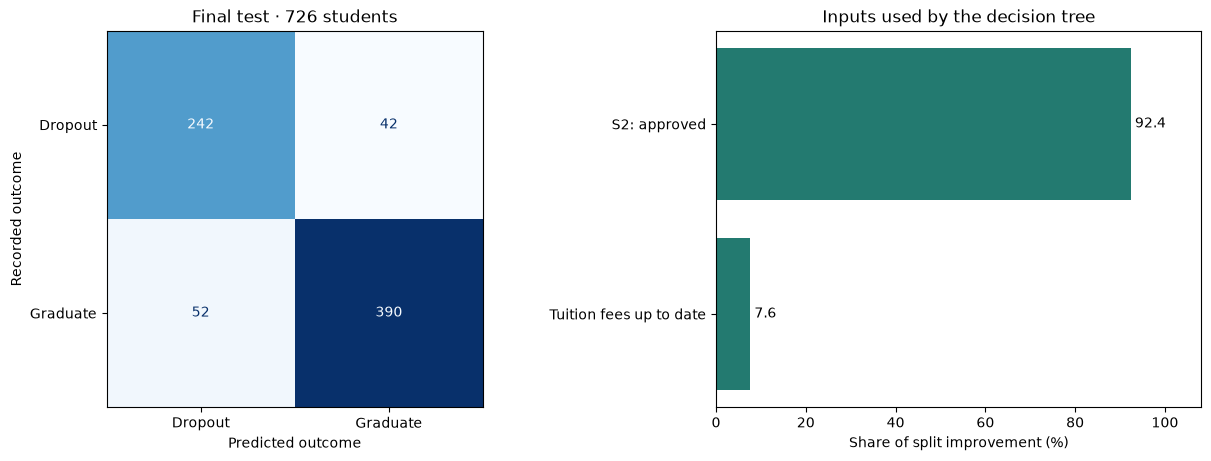

In [10]:
# Visual of the test errors and the main features.
output_dir.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=axes[0], colorbar=False, cmap="Blues", values_format="d")
axes[0].set(title="Final test · 726 students" if len(X_test) == 726 else "Final test", xlabel="Predicted outcome", ylabel="Recorded outcome")
top = importance[importance > 0].head(6).sort_values()
clean_labels = [name.replace(s1, "S1: ").replace(s2, "S2: ").replace("_", " ").capitalize() for name in top.index]
bars = axes[1].barh(clean_labels, 100 * top, color="#237a70")
axes[1].bar_label(bars, fmt="%.1f", padding=3)
axes[1].set(title="Inputs used by the decision tree", xlabel="Share of split improvement (%)",
            xlim=(0, max(100 * top) * 1.17))
fig.savefig(output_dir / "decision_tree_results.png", dpi=170, bbox_inches="tight")
plt.show()

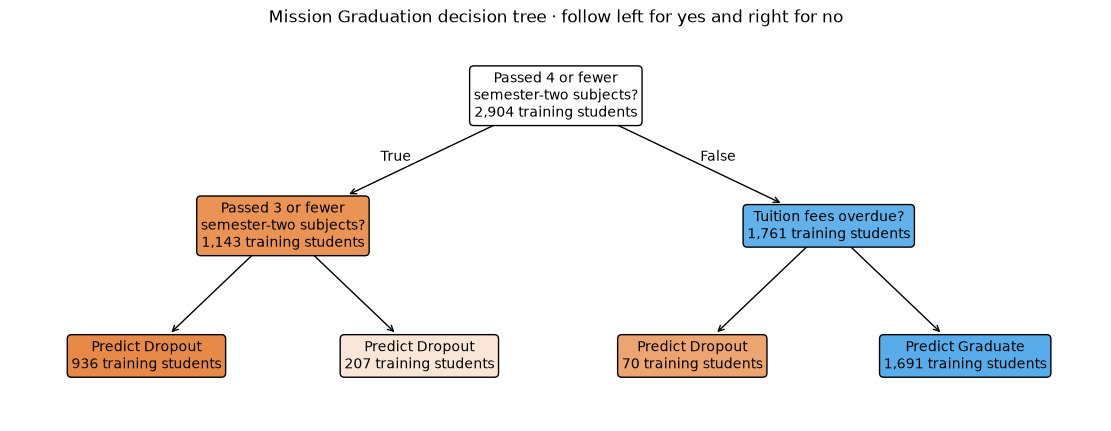

In [14]:
# Draw the fitted rules in subject counts and fee status so advisers can read the tree.
from sklearn.tree import plot_tree

def question(node):
    name = feature_names[model.tree_.feature[node]]
    field = name.split("__", 1)[1]
    threshold = model.tree_.threshold[node]
    if field in numeric:
        i = numeric.index(field)
        threshold = (threshold - scaler_for_plot.min_[i]) / scaler_for_plot.scale_[i]
    if field == s2 + "approved":
        return f"Passed {int(np.floor(threshold))} or fewer\nsemester-two subjects?"
    if field == "tuition_fees_up_to_date" and 0 <= threshold < 1:
        return "Tuition fees overdue?"
    return field.replace("_", " ") + f" ≤ {threshold:.2f}?"

scaler_for_plot = prep.named_transformers_["numerical"]
fig, ax = plt.subplots(figsize=(11, 4.2), layout="constrained")
boxes = plot_tree(model, ax=ax, node_ids=True, filled=True, rounded=True, fontsize=10)
for box in boxes:
    first_line = box.get_text().splitlines()[0]
    if first_line.startswith("node #"):
        node = int(first_line.split("#")[-1])
        if model.tree_.children_left[node] == model.tree_.children_right[node]:
            title = "Predict " + model.classes_[np.argmax(model.tree_.value[node])]
        else:
            title = question(node)
        box.set_text(title + f"\n{model.tree_.n_node_samples[node]:,} training students")
ax.set_title("Mission Graduation decision tree · follow left for yes and right for no", loc="center")
fig.savefig(output_dir / "decision_tree_rules.png", dpi=170, bbox_inches="tight")
plt.show()

In [15]:
# Give the predicted statuses and counts for enrolled students without treating them as outcomes.
enrolled_results = enrolled.copy()
enrolled_results["predicted_status"] = best.predict(enrolled[inputs])
dropout_position = list(best.classes_).index("Dropout")
enrolled_results["dropout_model_score"] = best.predict_proba(enrolled[inputs])[:, dropout_position]
counts = enrolled_results["predicted_status"].value_counts().reindex(labels, fill_value=0)
summary = pd.DataFrame({"students": counts, "percent": (100 * counts / len(enrolled_results)).round(1)})
print(summary.to_string())
print("Total scored:", int(counts.sum()))

                  students  percent
predicted_status                   
Dropout                477     60.1
Graduate               317     39.9
Total scored: 794


In [16]:
# Save the fitted tree and the results so this run can be reused.
model_dir.mkdir(exist_ok=True)
joblib.dump(best, model_dir / "cem_decision_tree.joblib", compress=3)
comparison.rename_axis("model").to_csv(output_dir / "validation_models.csv")
feature_results.rename_axis("feature_set").to_csv(output_dir / "validation_feature_sets.csv")
test_metrics.rename_axis("metric").to_csv(output_dir / "decision_tree_test.csv")
enrolled_results[["predicted_status", "dropout_model_score"]].to_csv(
    output_dir / "decision_tree_enrolled_predictions.csv", index_label="row_in_enrolled_csv")
split = pd.DataFrame({"split": "test", "validation_fold": 0}, index=labelled.index)
split.loc[X_train.index, "split"] = "train"
for fold, (_, val) in enumerate(folds, start=1):
    split.loc[X_train.index[val], "validation_fold"] = fold
split.to_csv(output_dir / "decision_tree_split.csv", index_label="row_in_selected_csv")
print("Saved model:", (model_dir / "cem_decision_tree.joblib").resolve())
print("Saved charts and result CSVs:", output_dir.resolve())

Saved model: C:\Users\cemko\Documents\Ironhack\Week_7\Day_1\mini_project_7\models\cem_decision_tree.joblib
Saved charts and result CSVs: C:\Users\cemko\Documents\Ironhack\Week_7\Day_1\mini_project_7\outputs\cem_decision_tree
